# Loss Functions: How a Model Knows It's Wrong
### A visual, low-math lecture that sets the stage for gradient descent

| Part | Topic |
|---|---|
| 0 | Setup and the big idea |
| 1 | A line through points: errors, squares, MSE |
| 2 | The derivative of MSE |
| 3 | Into 3D: a plane, and the loss *bowl* |
| 4 | Yes/no questions: cross-entropy |
| 5 | Wrap-up and teaser: rolling downhill |

**3D plots can be rotated with the mouse.**

If you want to really understand deep learning, read this book: https://udlbook.github.io/udlbook/

Its free of charge, and I will be using it all the time here. It's worth the time and effort

In [1]:
# If anything is missing:  !pip install numpy matplotlib ipywidgets plotly
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from ipywidgets import interact, FloatSlider, IntSlider, Checkbox, Layout
import plotly.graph_objects as go
from plotly.subplots import make_subplots
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass  # not in Colab

In [2]:
# Set some parameters for the figures so we dont need to define them all the time
%matplotlib inline
plt.rcParams.update({
    "figure.figsize": (9, 5.5), 
    "font.size": 13, 
    "axes.grid": True, 
    "grid.alpha": 0.3,
    "axes.spines.top": False, 
    "axes.spines.right": False,
})

# Define a bunch of colors to use in plots
BLUE, ORANGE, RED, GREEN, GREY = "#2f6db5", "#e07a1f", "#c0392b", "#2e8b57", "#7f8c8d"

def slider(label, lo, hi, value, step=0.05, live=True):
    return FloatSlider(value=value, min=lo, max=hi, step=step, description=label,
                       continuous_update=live, readout_format=".2f",
                       layout=Layout(width="500px"), style={"description_width": "140px"})

rng = np.random.default_rng(7)

## 0. The big idea

A model makes **guesses**. A **loss function** turns all of its mistakes into **one number**: *how wrong am I, overall?*

**Learning = turning the model's knobs until that number is as small as possible.**

Think of a golf score: one number sums up the whole round, and lower is better.

| Word | Plain meaning |
|---|---|
| **data** | examples we already know the answer for |
| **model** | a recipe that makes a guess, e.g. *price = w × size + b* |
| **parameters** (w, b) | the knobs of the recipe |
| **prediction** ŷ | the model's guess |
| **error** | real answer − guess |
| **loss** | one number that summarises all the errors |

# Part 1 · A line through points

We have 12 apartments. For each, we know its **size** and its **price**. Can a straight line describe the pattern?

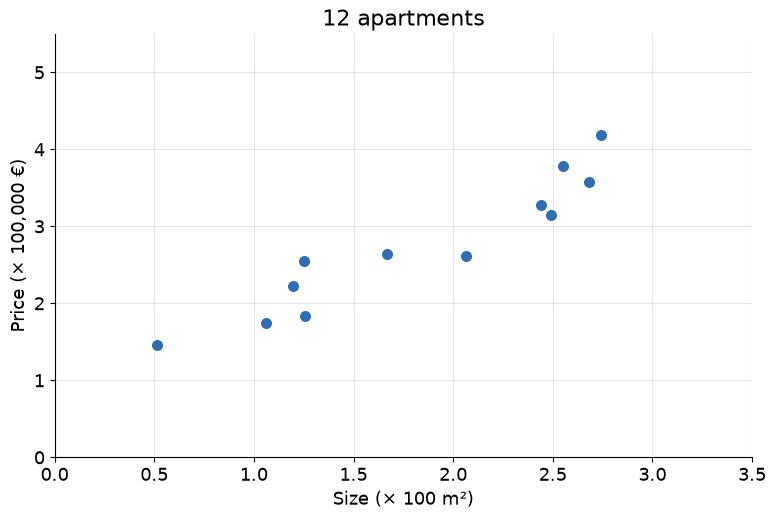

In [3]:
# 12 apartments: size (in 100 m²) and price (in 100,000 €)
n = 12
size = np.sort(rng.uniform(0.5, 3.0, n))
price = 0.8 + 1.2 * size + rng.normal(0, 0.35, n)

fig, ax = plt.subplots()
ax.scatter(size, price, s=80, color=BLUE, edgecolor="white", zorder=3)
ax.set(xlabel="Size (× 100 m²)", ylabel="Price (× 100,000 €)", title="12 apartments",
       xlim=(0, 3.5), ylim=(0, 5.5))
plt.show()

### 1.1 Make a guess, look at the misses

This is something you have probably done in physics trying to draw the best line that best fits all the points

Our model is a line: **price = w × size + b**.
- **w** (slope) says how much the price goes up per extra 100 m².
- **b** (intercept) is the starting price.

The red sticks are the **errors**: how far each real price is from our line.

In [4]:
xs = np.linspace(0, 3.5, 100)

def draw_line(w=0.3, b=2.5, show_errors=True):
    pred = w * size + b
    err = price - pred
    fig, ax = plt.subplots()
    ax.plot(xs, w * xs + b, color=ORANGE, lw=2.5, label=f"guess: price = {w:.2f} × size + {b:.2f}")
    if show_errors:
        ax.vlines(size, pred, price, color=RED, lw=2, alpha=0.8, label="errors (misses)")
    ax.scatter(size, price, s=80, color=BLUE, edgecolor="white", zorder=3)
    ax.set(xlabel="Size (× 100 m²)", ylabel="Price (× 100,000 €)", xlim=(0, 3.5), ylim=(0, 5.5))
    ax.set_title(f"Sum of errors = {err.sum():+.2f}     |     Average squared error = {np.mean(err**2):.3f}")
    ax.legend(loc="upper left")
    plt.show()

interact(draw_line, w=slider("slope  w", -1, 3, 0.3), b=slider("intercept  b", -1, 4, 2.5),
         show_errors=Checkbox(value=True, description="show errors"));

interactive(children=(FloatSlider(value=0.3, description='slope  w', layout=Layout(width='500px'), max=3.0, mi…

### 1.2 Why not just add up the errors?

Here is a clearly bad line: completely flat, at the average price.

Sum of raw errors: +0.000000 ← looks 'perfect'!
Average squared error: 0.676 ← tells the truth


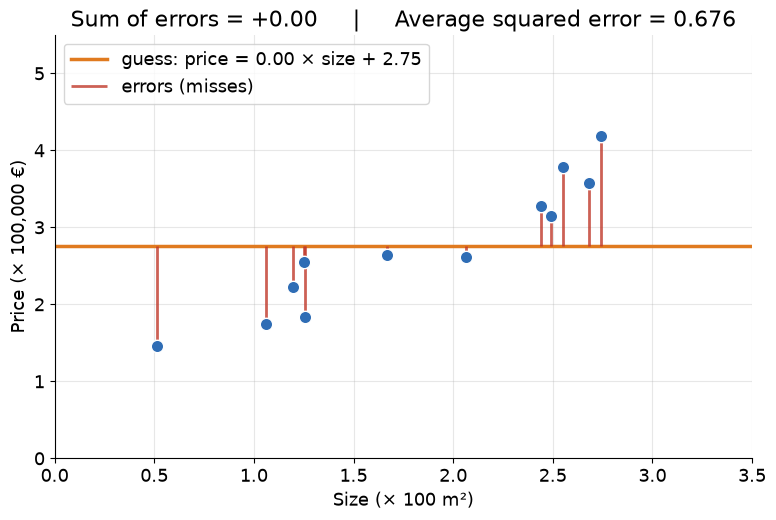

In [5]:
w_flat, b_flat = 0.0, price.mean()
err_flat = price - (w_flat * size + b_flat)
print(f"Sum of raw errors: {err_flat.sum():+.6f} ← looks 'perfect'!")
print(f"Average squared error: {np.mean(err_flat**2):.3f} ← tells the truth")
draw_line(w_flat, b_flat)

Misses **above** the line (+) and **below** the line (−) cancel each other out. We need every miss to count as *bad*, whatever its direction.

The fix: **square each error**. A square is always positive. And there is a nice picture for it…

### 1.3 Errors as actual squares

Each miss becomes a red square whose side is the length of the miss. **The loss is the average area of these squares.**

In [6]:
def draw_squares(w=0.3, b=2.5):
    pred = w * size + b
    err = price - pred
    sq = err**2
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1.4, 1]})
    ax.plot(np.linspace(0, 4.5, 100), w * np.linspace(0, 4.5, 100) + b, color=ORANGE, lw=2.5)
    for xi, yi, pi, e in zip(size, price, pred, err):
        ax.add_patch(Rectangle((xi, min(yi, pi)), abs(e), abs(e),
                               facecolor=RED, alpha=0.22, edgecolor=RED, lw=1))
    ax.scatter(size, price, s=60, color=BLUE, edgecolor="white", zorder=3)
    ax.set_aspect("equal")
    ax.set(xlim=(0, 4.5), ylim=(0, 5.5), xlabel="Size", ylabel="Price",
           title=f"Total red area = {sq.sum():.2f}")

    ax2.bar(np.arange(1, n + 1), sq, color=RED, alpha=0.6)
    ax2.axhline(sq.mean(), color="black", ls="--", lw=2, label=f"average area = MSE = {sq.mean():.3f}")
    ax2.set(xlabel="apartment #", ylabel="area of its square  (error²)", ylim=(0, 3),
            xticks=range(1, n + 1), title="Each apartment's square")
    ax2.legend(loc="upper right")
    plt.tight_layout(); plt.show()

interact(draw_squares, w=slider("slope  w", -1, 3, 0.3), b=slider("intercept  b", -1, 4, 2.5));

interactive(children=(FloatSlider(value=0.3, description='slope  w', layout=Layout(width='500px'), max=3.0, mi…

### 1.4 Squaring forgives small misses and punishes big ones

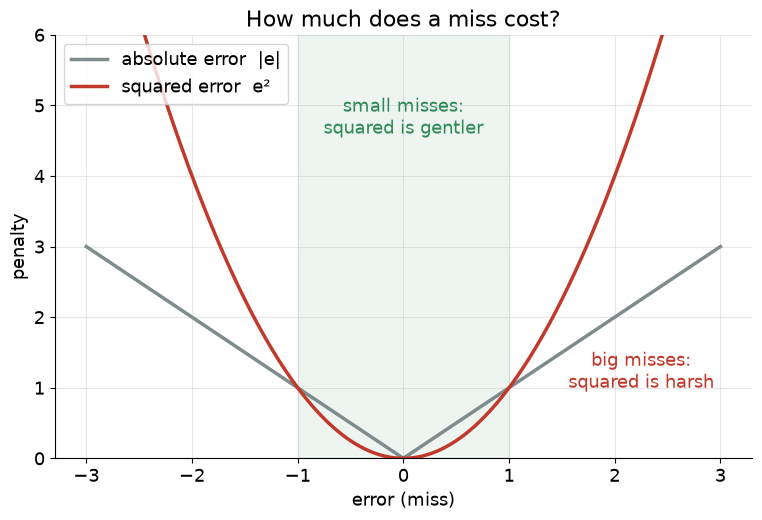

In [7]:
e = np.linspace(-3, 3, 400)
fig, ax = plt.subplots()
ax.axvspan(-1, 1, color=GREEN, alpha=0.08)
ax.plot(e, np.abs(e), color=GREY, lw=2.5, label="absolute error  |e|")
ax.plot(e, e**2, color=RED, lw=2.5, label="squared error  e²")
ax.text(0, 4.6, "small misses:\nsquared is gentler", ha="center", color=GREEN)
ax.text(2.25, 1.0, "big misses:\nsquared is harsh", ha="center", color=RED)
ax.set(xlabel="error (miss)", ylabel="penalty", ylim=(0, 6), title="How much does a miss cost?")
ax.legend(loc="upper left")
plt.show()

### 1.5 The formula, finally

Everything we've seen in one line:

$$
\text{MSE}(w, b) \;=\; \frac{1}{n}\sum_{i=1}^{n}\big(\,\underbrace{y_i}_{\text{real price}} - \underbrace{(w\,x_i + b)}_{\text{our guess } \hat y_i}\,\big)^2
$$

Read it aloud: *"for every apartment, take the miss, square it; then take the average."*

Note that the data ($x_i$, $y_i$) are **fixed**. The only things we can change are the knobs **w** and **b**. So the loss is really a function of the knobs.

### 1.6 The best possible line

Somebody already found the knob settings with the smallest possible area:

Best line:  price = 1.07 × size + 0.81
Smallest possible MSE = 0.074


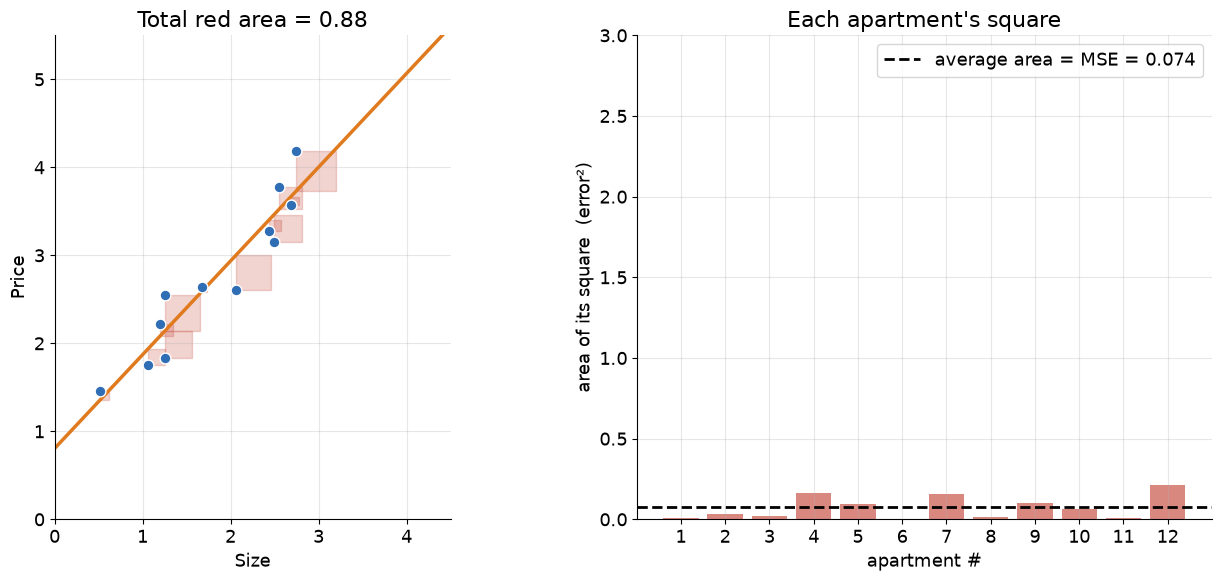

In [8]:
w_best, b_best = np.polyfit(size, price, 1)
def mse(w, b, x=size, y=price):
    return np.mean((y - (w * x + b))**2)

print(f"Best line:  price = {w_best:.2f} × size + {b_best:.2f}")
print(f"Smallest possible MSE = {mse(w_best, b_best):.3f}")
draw_squares(w_best, b_best)

*"How would a computer find these knob settings without trying every possible combination?"* 

Answer: look at which way the loss goes **downhill** when you nudge a knob. That "which way is downhill" is exactly the **Derivative**.

---
## Cacluclus Time: the derivative of MSE

**Step 1: one apartment only.** Call the miss $e = y - (wx + b)$. Its loss is $\ell = e^2$.

**Step 2: chain rule, in words:** *"how loss changes with the knob = how loss changes with the miss × how the miss changes with the knob."*

$$
\frac{d\ell}{de} = 2e, \qquad \frac{\partial e}{\partial w} = -x, \qquad \frac{\partial e}{\partial b} = -1
$$

**Step 3: average over all apartments:**

$$
\frac{\partial\,\text{MSE}}{\partial w} = -\frac{2}{n}\sum_i x_i\,\big(y_i - \hat y_i\big),
\qquad
\frac{\partial\,\text{MSE}}{\partial b} = -\frac{2}{n}\sum_i \big(y_i - \hat y_i\big)
$$

**Step 4: what it means:** the sign says *which way is uphill*, and the size says *how steep*. To go downhill, move the knob **the opposite way**.

# Deriving MSE for Simple Linear Regression (parameters $w$ and $b$)

## 1. The Model

For a single input variable $x$, the prediction is:

$$
\hat{y}_i = w x_i + b
$$

where $w$ is the weight (slope) and $b$ is the bias (intercept).

## 2. The Error for One Example

The residual (error) for example $i$ is the difference between the true value and the prediction:

$$
e_i = y_i - \hat{y}_i = y_i - (w x_i + b)
$$

## 3. The Mean Squared Error

Square each error (so positive and negative errors don't cancel, and large errors are penalized more), then average over all $n$ examples:

$$
J(w, b) = \frac{1}{n} \sum_{i=1}^{n} \left( y_i - (w x_i + b) \right)^2
$$


## 4. Partial Derivative with Respect to $w$

Apply the chain rule. The outer function is $u^2$ with $u = y_i - w x_i - b$, and $\frac{\partial u}{\partial w} = -x_i$:

$$
\frac{\partial J}{\partial w}
= \frac{1}{n} \sum_{i=1}^{n} 2 \left( y_i - w x_i - b \right) \cdot (-x_i)
$$

Simplify:

$$
\boxed{\frac{\partial J}{\partial w} = -\frac{2}{n} \sum_{i=1}^{n} x_i \left( y_i - w x_i - b \right)}
$$

## 5. Partial Derivative with Respect to $b$

Same chain rule, but now $\frac{\partial u}{\partial b} = -1$:

$$
\frac{\partial J}{\partial b}
= \frac{1}{n} \sum_{i=1}^{n} 2 \left( y_i - w x_i - b \right) \cdot (-1)
$$

Simplify:

$$
\boxed{\frac{\partial J}{\partial b} = -\frac{2}{n} \sum_{i=1}^{n} \left( y_i - w x_i - b \right)}
$$


## 6. Closed-Form Solution (Setting Gradients to Zero)

Because $J(w,b)$ is convex, the minimum is where both partial derivatives equal zero.

### 6a. Solve for $b$

Set $\frac{\partial J}{\partial b} = 0$:

$$
\sum_{i=1}^{n} \left( y_i - w x_i - b \right) = 0
$$

$$
\sum_{i=1}^{n} y_i - w \sum_{i=1}^{n} x_i - n b = 0
$$

Divide by $n$, using $\bar{x} = \frac{1}{n}\sum x_i$ and $\bar{y} = \frac{1}{n}\sum y_i$:

$$
\boxed{b = \bar{y} - w \bar{x}}
$$

### 6b. Solve for $w$

Set $\frac{\partial J}{\partial w} = 0$:

$$
\sum_{i=1}^{n} x_i \left( y_i - w x_i - b \right) = 0
$$

Substitute $b = \bar{y} - w\bar{x}$:

$$
\sum_{i=1}^{n} x_i \left( (y_i - \bar{y}) - w (x_i - \bar{x}) \right) = 0
$$

$$
\sum_{i=1}^{n} x_i (y_i - \bar{y}) = w \sum_{i=1}^{n} x_i (x_i - \bar{x})
$$

Since $\sum_{i=1}^{n} (y_i - \bar{y}) = 0$ and $\sum_{i=1}^{n} (x_i - \bar{x}) = 0$, we can subtract $\bar{x}$ times each of those (which is zero) without changing anything, replacing $x_i$ with $(x_i - \bar{x})$ on both sides:

$$
\sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y}) = w \sum_{i=1}^{n} (x_i - \bar{x})^2
$$

Therefore:

$$
\boxed{w = \frac{\sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})}{\sum_{i=1}^{n} (x_i - \bar{x})^2}
= \frac{\operatorname{Cov}(x, y)}{\operatorname{Var}(x)}}
$$

## 7. Summary

| Quantity | Formula |
|---|---|
| Model | $\hat{y}_i = w x_i + b$ |
| Loss | $J(w,b) = \frac{1}{n}\sum (y_i - \hat{y}_i)^2$ |
| $\partial J / \partial w$ | $-\frac{2}{n}\sum x_i (y_i - \hat{y}_i)$ |
| $\partial J / \partial b$ | $-\frac{2}{n}\sum (y_i - \hat{y}_i)$ |
| Optimal $w$ | $\frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sum (x_i - \bar{x})^2}$ |
| Optimal $b$ | $\bar{y} - w\bar{x}$ |

### 1.7 The derivative is the slope of the loss curve

Keep **b** fixed at its best value and turn only the **w** knob. The loss traces a U-shaped curve. The orange dashed line is the tangent, and its slope is what our formula from the board gives.

In [9]:
def grad_mse(w, b, x=size, y=price):
    e = y - (w * x + b)
    return -2 * np.mean(x * e), -2 * np.mean(e)

ws = np.linspace(-1, 3, 300)
L_w = np.array([mse(wi, b_best) for wi in ws])

def draw_slope(w=0.0):
    b = b_best
    dw, _ = grad_mse(w, b)
    fig, ax = plt.subplots()
    ax.plot(ws, L_w, color=BLUE, lw=2.5, label="loss as we turn the w knob")
    t = np.array([w - 0.5, w + 0.5])
    ax.plot(t, mse(w, b) + dw * (t - w), color=ORANGE, lw=2.5, ls="--", label=f"tangent: slope = {dw:+.2f}")
    ax.scatter([w], [mse(w, b)], color=ORANGE, s=140, edgecolor="black", zorder=3)
    ax.scatter([w_best], [mse(w_best, b)], marker="*", color=RED, s=250, zorder=3, label="bottom")
    advice = "→ increase w" if dw < -0.05 else ("← decrease w" if dw > 0.05 else "✓ (almost) at the bottom")
    ax.set(xlabel="slope w   (b fixed at its best value)", ylabel="MSE", ylim=(0, L_w.max() * 1.05),
           title=f"derivative = {dw:+.2f}     advice: {advice}")
    ax.legend(loc="upper center")
    plt.show()

interact(draw_slope, w=slider("slope  w", -1, 3, 0.0));

interactive(children=(FloatSlider(value=0.0, description='slope  w', layout=Layout(width='500px'), max=3.0, mi…

In [10]:
w0, b0, h = 0.5, 1.0, 1e-5
nudge_w = (mse(w0 + h, b0) - mse(w0 - h, b0)) / (2 * h)
nudge_b = (mse(w0, b0 + h) - mse(w0, b0 - h)) / (2 * h)
form_w, form_b = grad_mse(w0, b0)
print(f"{'':12}{'board formula':>16}{'tiny nudge':>14}")
print(f"{'d/dw':12}{form_w:16.5f}{nudge_w:14.5f}")
print(f"{'d/db':12}{form_b:16.5f}{nudge_b:14.5f}")

               board formula    tiny nudge
d/dw                -3.66582      -3.66582
d/db                -1.67811      -1.67811


# Part 2 · Into 3D

### 2.1 Two inputs: from a line to a plane

Now each apartment has **size** *and* **number of rooms**. Our model becomes a flat sheet (a **plane**):

$$\text{price} = w_1 \cdot \text{size} + w_2 \cdot \text{rooms} + b$$

Same idea as before: red sticks are misses, and the loss is the average squared miss. Nothing new, just one more dimension.

In [11]:
n2 = 40
size2 = rng.uniform(0.5, 3.0, n2)
rooms = np.clip(np.round(1 + 1.2 * size2 + rng.normal(0, 0.8, n2)), 1, 6)
price2 = 0.4 + 0.9 * size2 + 0.3 * rooms + rng.normal(0, 0.3, n2)

gs, gr = np.meshgrid(np.linspace(0.5, 3, 20), np.linspace(1, 6, 20))
CAMERA = dict(eye=dict(x=1.6, y=-1.6, z=0.9))

def draw_plane(w1=0.5, w2=0.1, b=1.5, show_errors=True):
    pred = w1 * size2 + w2 * rooms + b
    err = price2 - pred
    fig = go.Figure()
    fig.add_surface(x=gs, y=gr, z=w1 * gs + w2 * gr + b, opacity=0.5, showscale=False,
                    colorscale=[[0, ORANGE], [1, ORANGE]], name="our plane")
    fig.add_scatter3d(x=size2, y=rooms, z=price2, mode="markers",
                      marker=dict(size=4, color=BLUE), name="apartments")
    if show_errors:
        X, Y, Z = [], [], []
        for xi, ri, yi, pi in zip(size2, rooms, price2, pred):
            X += [xi, xi, None]; Y += [ri, ri, None]; Z += [yi, pi, None]
        fig.add_scatter3d(x=X, y=Y, z=Z, mode="lines", line=dict(color=RED, width=4), name="errors")
    fig.update_layout(
        title=f"price = {w1:.2f}·size + {w2:.2f}·rooms + {b:.2f}     |     MSE = {np.mean(err**2):.3f}",
        scene=dict(xaxis_title="size", yaxis_title="rooms", zaxis_title="price",
                   zaxis=dict(range=[0, 7]), camera=CAMERA),
        height=620, margin=dict(l=0, r=0, t=50, b=0))
    fig.show()

interact(draw_plane,
         w1=slider("size weight  w₁", -1, 2, 0.5, live=False),
         w2=slider("rooms weight  w₂", -1, 2, 0.1, live=False),
         b=slider("intercept  b", -2, 4, 1.5, live=False),
         show_errors=Checkbox(value=True, description="show errors"));

interactive(children=(FloatSlider(value=0.5, continuous_update=False, description='size weight  w₁', layout=La…

Best plane: price = 0.70·size + 0.34·rooms + 0.58


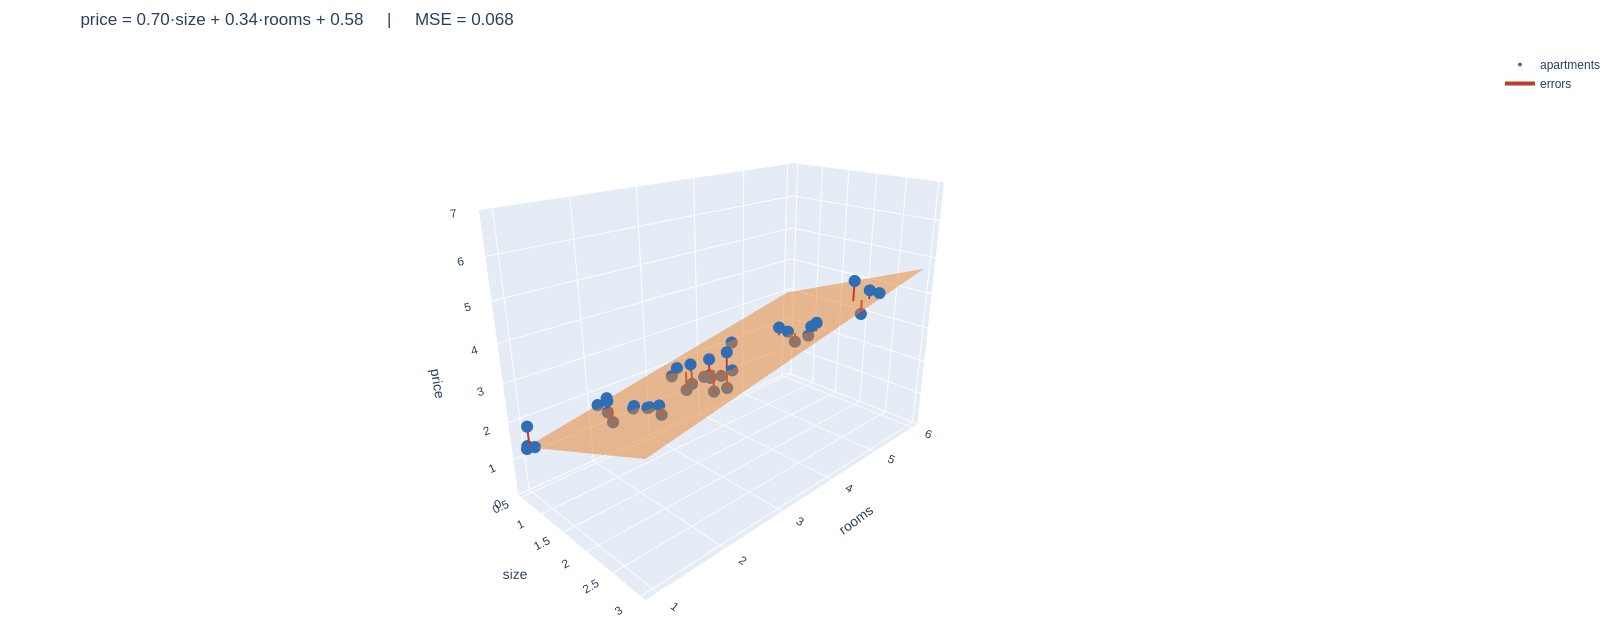

In [12]:
# The best plane (the smallest possible average squared miss)
A = np.column_stack([size2, rooms, np.ones(n2)])
w1_best, w2_best, b2_best = np.linalg.lstsq(A, price2, rcond=None)[0]
print(f"Best plane: price = {w1_best:.2f}·size + {w2_best:.2f}·rooms + {b2_best:.2f}")
draw_plane(w1_best, w2_best, b2_best)

### 2.2 The most important picture: the loss *bowl*

Back to the simple line with two knobs, **w** and **b**. Imagine trying **every** combination of knobs and, for each, plotting how bad that line is (its MSE) as a height.

- Every **point on the floor** = one possible line.
- The **height** = how wrong that line is.
- The **bottom of the bowl** = the best line (red dot).

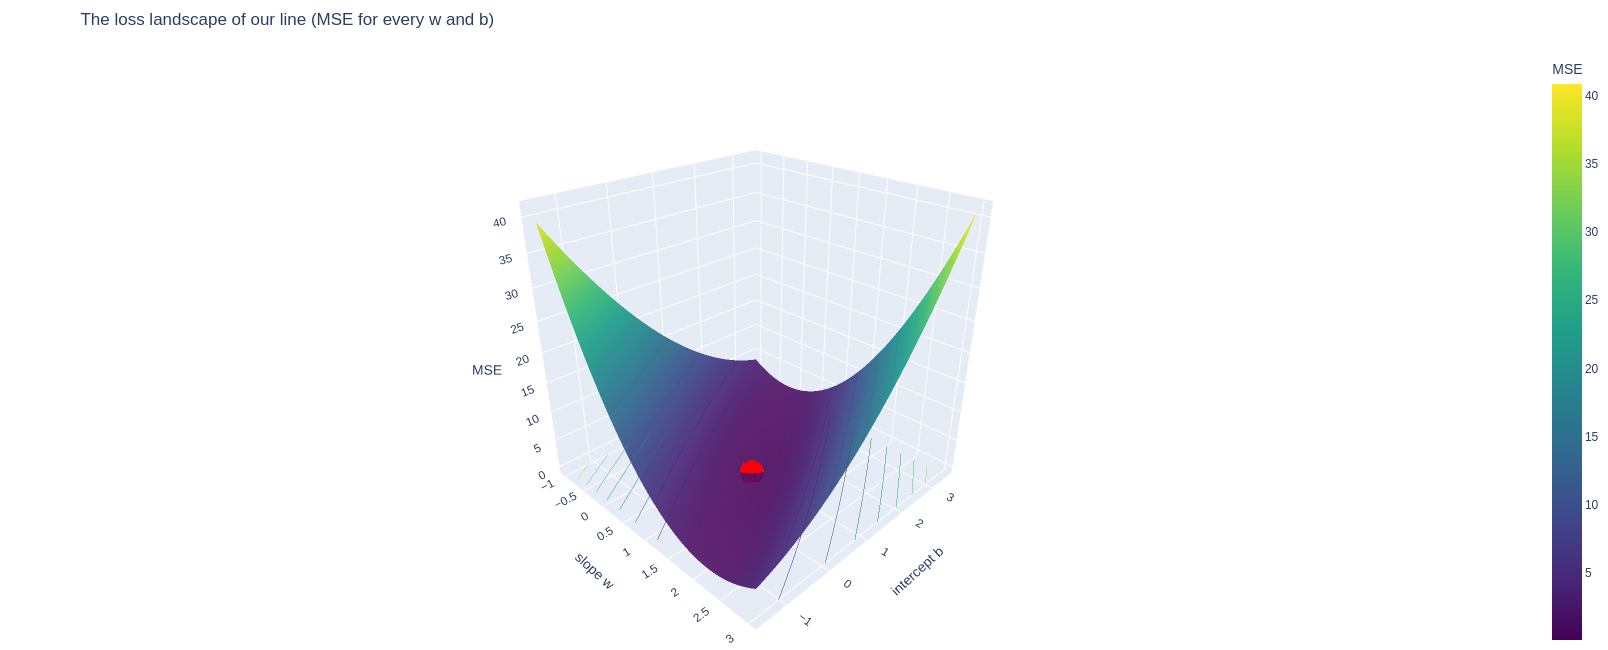

In [13]:
W = np.linspace(-1, 3, 120)
B = np.linspace(-1.5, 3.5, 120)
WW, BB = np.meshgrid(W, B)
LOSS = np.mean((price - (WW[..., None] * size + BB[..., None]))**2, axis=-1)

fig = go.Figure(go.Surface(x=WW, y=BB, z=LOSS, colorscale="Viridis", opacity=0.93,
                           colorbar=dict(title="MSE"),
                           contours_z=dict(show=True, usecolormap=True, project_z=True)))
fig.add_scatter3d(x=[w_best], y=[b_best], z=[mse(w_best, b_best)], mode="markers",
                  marker=dict(size=8, color="red"), name="best line")
fig.update_layout(title="The loss landscape of our line (MSE for every w and b)",
                  scene=dict(xaxis_title="slope w", yaxis_title="intercept b", zaxis_title="MSE",
                             camera=dict(eye=dict(x=1.5, y=-1.5, z=1.1))),
                  height=650, margin=dict(l=0, r=0, t=50, b=0))
fig.show()

### 2.3 Two views of the same thing

**Left:** the line on the data. **Right:** the same line as a single dot on a *map* of the bowl, seen from above, like a hiking map with contour lines. Darker = lower = better.

Every time you release a slider, your position is added to the trail. Try to "hike" to the star by hand. Re-run the cell to clear the trail.

In [14]:
trail = []
LOG_LOSS = np.log(LOSS)

def draw_linked(w=0.0, b=3.0):
    trail.append((w, b))
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.8))
    ax1.plot(xs, w * xs + b, color=ORANGE, lw=2.5)
    ax1.vlines(size, w * size + b, price, color=RED, lw=2, alpha=0.8)
    ax1.scatter(size, price, s=70, color=BLUE, edgecolor="white", zorder=3)
    ax1.set(xlim=(0, 3.5), ylim=(0, 5.5), xlabel="Size", ylabel="Price",
            title=f"The line     MSE = {mse(w, b):.3f}")

    ax2.contourf(WW, BB, LOG_LOSS, 30, cmap="viridis")
    ax2.contour(WW, BB, LOG_LOSS, 15, colors="white", linewidths=0.4, alpha=0.6)
    tw, tb = zip(*trail)
    ax2.plot(tw, tb, "o-", color="white", ms=4, lw=1.2, alpha=0.8)
    ax2.scatter([w], [b], s=170, color=ORANGE, edgecolor="black", zorder=4, label="you are here")
    ax2.scatter([w_best], [b_best], marker="*", s=320, color=RED, edgecolor="white", zorder=4, label="bottom")
    ax2.set(xlabel="slope w", ylabel="intercept b", title="The map of the bowl (seen from above)")
    ax2.grid(False); ax2.legend(loc="upper right")
    plt.tight_layout(); plt.show()

interact(draw_linked, w=slider("slope  w", -1, 3, 0.0, live=False), b=slider("intercept  b", -1.5, 3.5, 3.0, live=False));

interactive(children=(FloatSlider(value=0.0, continuous_update=False, description='slope  w', layout=Layout(wi…

# Part 3 · Yes/no questions: cross-entropy

New problem. We know how many hours each student studied, and whether they **passed (1)** or **failed (0)**. We want the model to tell us the **chance of passing**.

In [15]:
n3 = 30
hours = np.sort(rng.uniform(0, 10, n3))
passed = (rng.uniform(size=n3) < 1 / (1 + np.exp(-0.7 * (hours - 5)))).astype(float)
cls_color = np.where(passed == 1, GREEN, RED)

def scatter_students(ax):
    ax.scatter(hours, passed, s=80, c=cls_color, edgecolor="white", zorder=3)
    ax.set(xlabel="Hours studied", yticks=[0, 0.5, 1], xlim=(-0.5, 10.5))

print(f"{int(passed.sum())} passed, {int(n3 - passed.sum())} failed")

19 passed, 11 failed


### 3.1 Why a straight line doesn't fit

If we force a straight line through 0/1 answers, it happily predicts a **120 % chance** or a **−20 % chance**. Neither makes sense.

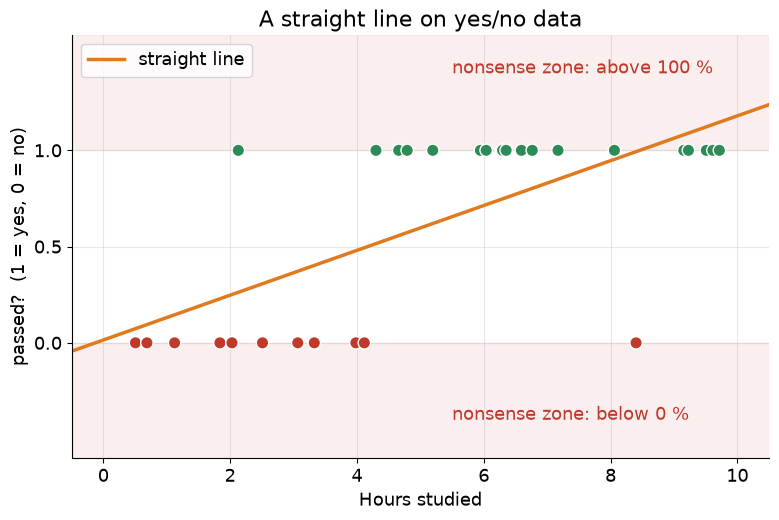

In [16]:
wl, bl = np.polyfit(hours, passed, 1)
hx = np.linspace(-0.5, 10.5, 300)
fig, ax = plt.subplots()
ax.axhspan(1, 1.6, color=RED, alpha=0.08); ax.axhspan(-0.6, 0, color=RED, alpha=0.08)
ax.text(5.5, 1.4, "nonsense zone: above 100 %", color=RED)
ax.text(5.5, -0.4, "nonsense zone: below 0 %", color=RED)
ax.plot(hx, wl * hx + bl, color=ORANGE, lw=2.5, label="straight line")
scatter_students(ax)
ax.set(ylim=(-0.6, 1.6), ylabel="passed?  (1 = yes, 0 = no)", title="A straight line on yes/no data")
ax.legend(loc="upper left"); plt.show()

### 3.2 The S-curve (sigmoid): a "squasher"

The sigmoid takes **any number** and squashes it into the range **0 to 1**, so we can read the output as a probability:

$$p = \sigma(w\cdot\text{hours} + b) = \frac{1}{1 + e^{-(w\cdot \text{hours} + b)}}$$

The inside is the same old line. The sigmoid just bends it into an S.

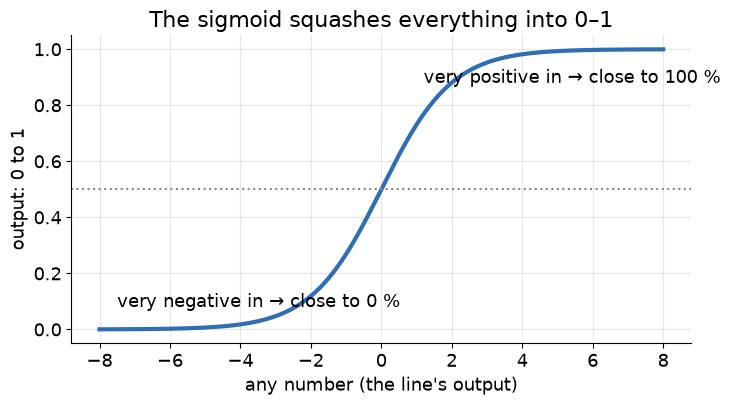

In [17]:
z = np.linspace(-8, 8, 300)
sigmoid = lambda t: 1 / (1 + np.exp(-np.clip(t, -500, 500)))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(z, sigmoid(z), color=BLUE, lw=3)
ax.axhline(0.5, color=GREY, ls=":")
ax.text(-7.5, 0.08, "very negative in → close to 0 %"); ax.text(1.2, 0.88, "very positive in → close to 100 %")
ax.set(xlabel="any number (the line's output)", ylabel="output: 0 to 1", title="The sigmoid squashes everything into 0–1")
plt.show()

In [18]:
def draw_sigmoid(w=1.0, b=-5.0):
    fig, ax = plt.subplots()
    ax.plot(hx, sigmoid(w * hx + b), color=ORANGE, lw=3, label="predicted chance of passing")
    ax.axhline(0.5, color=GREY, ls=":")
    if abs(w) > 1e-6 and -0.5 < -b / w < 10.5:
        ax.axvline(-b / w, color=GREY, ls="--")
        ax.text(-b / w + 0.15, 0.52, f"50/50 at {-b / w:.1f} h", color=GREY)
    scatter_students(ax)
    ax.set(ylim=(-0.08, 1.08), ylabel="chance of passing", title=f"p = σ({w:.2f} × hours + {b:.2f})")
    ax.legend(loc="upper left"); plt.show()

interact(draw_sigmoid, w=slider("sharpness  w", -1, 4, 1.0), b=slider("shift  b", -20, 5, -5.0, step=0.1));

interactive(children=(FloatSlider(value=1.0, description='sharpness  w', layout=Layout(width='500px'), max=4.0…

### 3.3 Scoring a probability: the "surprise penalty"

The model says *"80 % chance this student passes."* How do we punish that guess?

- If the student **passed**, the model wasn't very surprised → **small penalty**.
- If the student **failed**, the model was surprised → **bigger penalty**.
- If the model said **99 %** and the student **failed** → **huge penalty**. Being *confidently wrong* is the worst sin.

The curve that does exactly this is **−log(p)**: zero when you gave the right answer 100 %, shooting up as you gave it less and less.

In [19]:
pp = np.linspace(0.001, 0.999, 500)

def draw_surprise(p=0.8):
    fig, ax = plt.subplots()
    ax.plot(pp, -np.log(pp), color=GREEN, lw=2.5, label="if the student PASSED:  −log(p)")
    ax.plot(pp, -np.log(1 - pp), color=RED, lw=2.5, label="if the student FAILED:  −log(1 − p)")
    ax.scatter([p], [-np.log(p)], color=GREEN, s=140, edgecolor="black", zorder=3)
    ax.scatter([p], [-np.log(1 - p)], color=RED, s=140, edgecolor="black", zorder=3)
    ax.axvline(p, color=GREY, ls=":")
    ax.set(xlabel="model's predicted chance of passing  p", ylabel="penalty (surprise)", ylim=(0, 5), xlim=(0, 1),
           title=f"Model says {p:.0%}  →  penalty if passed: {-np.log(p):.2f}   |   if failed: {-np.log(1 - p):.2f}")
    ax.legend(loc="upper center"); plt.show()

interact(draw_surprise, p=slider("predicted  p", 0.01, 0.99, 0.8, step=0.01));

interactive(children=(FloatSlider(value=0.8, description='predicted  p', layout=Layout(width='500px'), max=0.9…

In [20]:
print(f"{'model said':>12}{'penalty if PASSED':>20}{'penalty if FAILED':>20}")
for p in [0.99, 0.9, 0.7, 0.5, 0.3, 0.1, 0.01]:
    print(f"{p:>11.0%} {-np.log(p):>19.2f} {-np.log(1 - p):>19.2f}")

  model said   penalty if PASSED   penalty if FAILED
        99%                0.01                4.61
        90%                0.11                2.30
        70%                0.36                1.20
        50%                0.69                0.69
        30%                1.20                0.36
        10%                2.30                0.11
         1%                4.61                0.01


### 3.4 Cross-entropy = the average surprise

Give every student their surprise penalty and take the **average**. That's the **cross-entropy loss**.

Top: the S-curve and the students. Bottom: each student's penalty. Try to make the bars small.

In [21]:
def cross_entropy(w, b, x=hours, y=passed):
    p = np.clip(sigmoid(w * x + b), 1e-12, 1 - 1e-12)
    return np.mean(-(y * np.log(p) + (1 - y) * np.log(1 - p)))

def draw_ce(w=0.5, b=-1.0):
    p = np.clip(sigmoid(w * hours + b), 1e-12, 1 - 1e-12)
    pen = -(passed * np.log(p) + (1 - passed) * np.log(1 - p))
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8.5), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]})
    ax1.plot(hx, sigmoid(w * hx + b), color=ORANGE, lw=3)
    ax1.vlines(hours, p, passed, color=GREY, lw=1.2, alpha=0.7)
    scatter_students(ax1)
    ax1.set(ylim=(-0.08, 1.08), ylabel="chance of passing", title=f"Cross-entropy (average surprise) = {pen.mean():.3f}")
    ax2.bar(hours, np.minimum(pen, 5), width=0.22, color=cls_color, alpha=0.75)
    ax2.axhline(pen.mean(), color="black", ls="--", lw=2, label="average")
    ax2.set(ylim=(0, 5), xlabel="Hours studied", ylabel="this student's penalty")
    ax2.legend(loc="upper right")
    plt.tight_layout(); plt.show()

interact(draw_ce, w=slider("sharpness  w", -1, 4, 0.5), b=slider("shift  b", -20, 5, -1.0, step=0.1));

interactive(children=(FloatSlider(value=0.5, description='sharpness  w', layout=Layout(width='500px'), max=4.0…

Best S-curve: p = σ(0.82 × hours + -3.33)   cross-entropy = 0.379


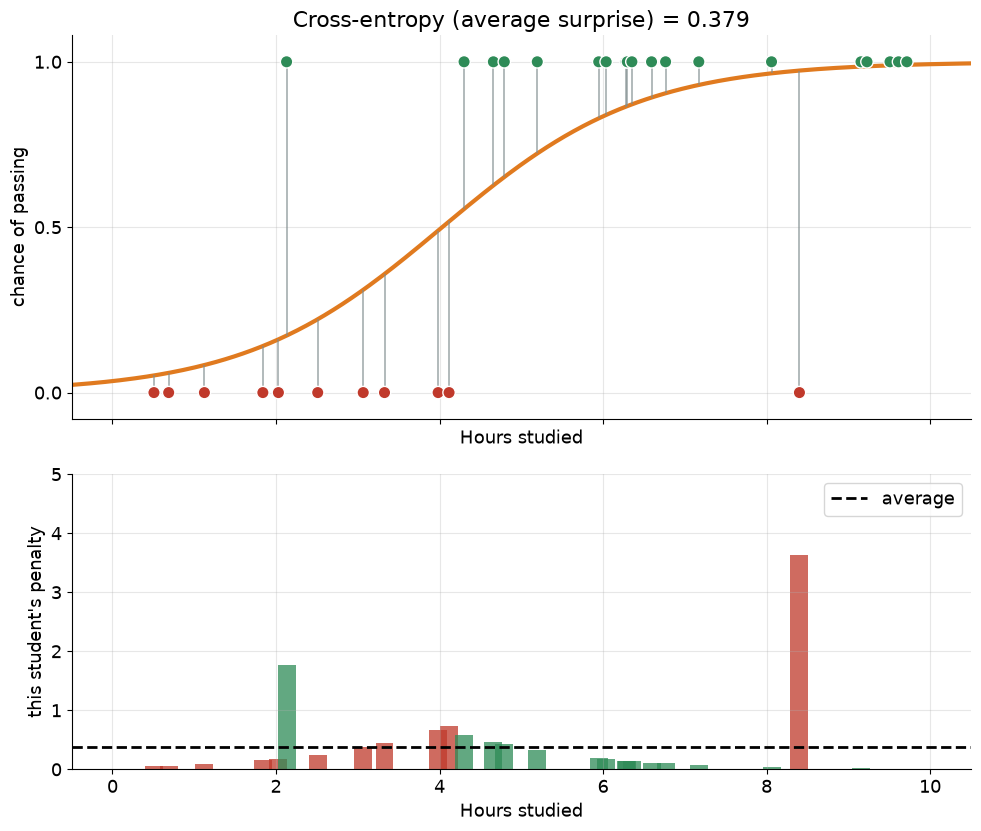

In [22]:
# Behind the scenes: find the best S-curve (you don't need to show this code)
X3 = np.column_stack([hours, np.ones(n3)])
theta = np.zeros(2)
for _ in range(30):                                   # Newton's method, converges in a few steps
    p = sigmoid(X3 @ theta)
    H = X3.T @ (X3 * (p * (1 - p))[:, None])
    theta -= np.linalg.solve(H, X3.T @ (p - passed))
w_ce, b_ce = theta
print(f"Best S-curve: p = σ({w_ce:.2f} × hours + {b_ce:.2f})   cross-entropy = {cross_entropy(w_ce, b_ce):.3f}")
draw_ce(w_ce, b_ce)

### 3.5 Why not just use squared error again?

Two reasons, both visual.

**Reason 1: squared error is too polite.** If the student passed and the model said 1 %, the squared error is at most 1. Cross-entropy says that's a disaster.

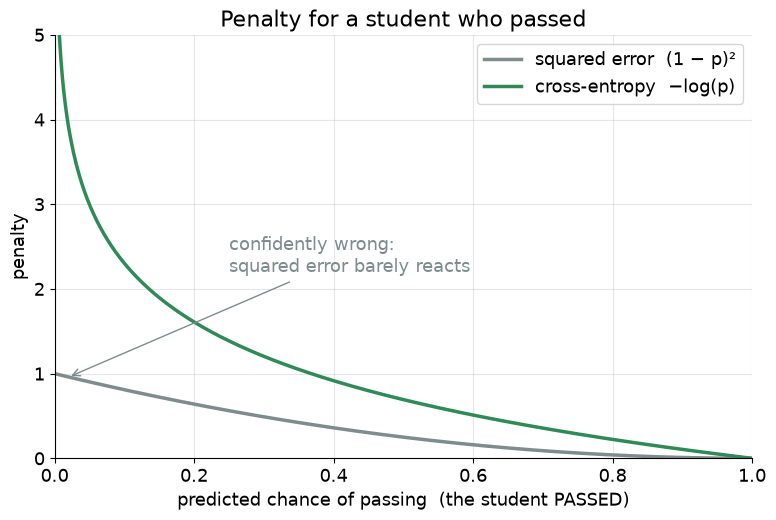

In [23]:
fig, ax = plt.subplots()
ax.plot(pp, (1 - pp)**2, color=GREY, lw=2.5, label="squared error  (1 − p)²")
ax.plot(pp, -np.log(pp), color=GREEN, lw=2.5, label="cross-entropy  −log(p)")
ax.annotate("confidently wrong:\nsquared error barely reacts", xy=(0.02, 0.96), xytext=(0.25, 2.2),
            arrowprops=dict(arrowstyle="->", color=GREY), color=GREY)
ax.set(xlabel="predicted chance of passing  (the student PASSED)", ylabel="penalty", ylim=(0, 5), xlim=(0, 1),
       title="Penalty for a student who passed")
ax.legend(loc="upper right"); plt.show()

**Reason 2: the landscape.** Put squared error on top of the S-curve and the bowl gets **flat plateaus**. A ball placed there would barely know which way to roll. Cross-entropy gives a smooth, bowl-like shape that always slopes towards the bottom.

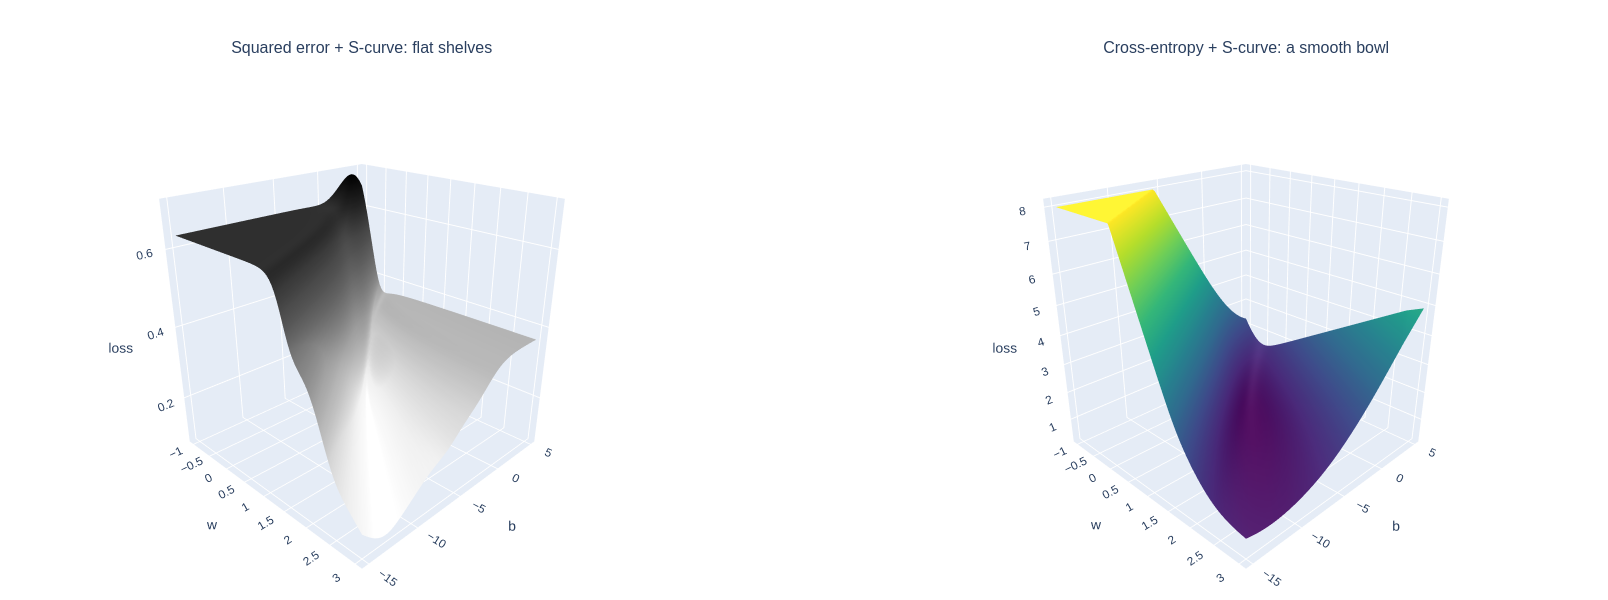

In [24]:
W3, B3 = np.meshgrid(np.linspace(-1, 3, 90), np.linspace(-15, 5, 90))
P3 = np.clip(sigmoid(W3[..., None] * hours + B3[..., None]), 1e-12, 1 - 1e-12)
MSE3 = np.mean((passed - P3)**2, axis=-1)
CE3 = np.mean(-(passed * np.log(P3) + (1 - passed) * np.log(1 - P3)), axis=-1)

fig = make_subplots(rows=1, cols=2, specs=[[{"type": "surface"}, {"type": "surface"}]],
                    subplot_titles=["Squared error + S-curve: flat shelves", "Cross-entropy + S-curve: a smooth bowl"])
fig.add_trace(go.Surface(x=W3, y=B3, z=MSE3, colorscale="Greys", showscale=False), 1, 1)
fig.add_trace(go.Surface(x=W3, y=B3, z=np.minimum(CE3, 8), colorscale="Viridis", showscale=False), 1, 2)
cam = dict(eye=dict(x=1.6, y=-1.6, z=1.0))
fig.update_layout(height=600, margin=dict(l=0, r=0, t=60, b=0),
                  scene=dict(xaxis_title="w", yaxis_title="b", zaxis_title="loss", camera=cam),
                  scene2=dict(xaxis_title="w", yaxis_title="b", zaxis_title="loss", camera=cam))
fig.show()

### 3.6 The cross-entropy formula

$$
\text{CE}(w,b) = -\frac{1}{n}\sum_{i=1}^{n}\Big[\;\underbrace{y_i \log p_i}_{\text{active if passed}} \;+\; \underbrace{(1 - y_i)\log(1 - p_i)}_{\text{active if failed}}\;\Big]
$$

It looks scary, but since $y_i$ is either 0 or 1, **only one of the two terms is "on" for each student**. It's just the surprise penalty from 3.3, averaged.

# Part 4 · Wrap-up and teaser

| Problem | Model's output | Loss | In one sentence |
|---|---|---|---|
| Predict a **number** (price) | any number | **MSE** | average area of the squared misses |
| Predict **yes / no** | a probability (0–1) | **Cross-entropy** | average surprise; confidently wrong is very expensive |

**The loss is one number. Choosing its formula is choosing what "wrong" means. Learning means getting to the bottom of its landscape.**

### Teaser: rolling downhill

Use the derivative from the board as directions: *take a small step in the downhill direction, then repeat.* That's **gradient descent**, next lecture's topic.

- **learning rate** = how big each step is
- **steps** = how many times we repeat

In [25]:
def roll_downhill(learning_rate=0.05, steps=30):
    w, b = -0.5, 3.0
    path = [(w, b)]
    for _ in range(steps):
        dw, db = grad_mse(w, b)                       # the formula from the board
        w, b = w - learning_rate * dw, b - learning_rate * db
        path.append((w, b))
        if abs(w) > 1e3 or abs(b) > 1e3:
            break
    path = np.array(path)
    losses = np.array([mse(pw, pb) for pw, pb in path])

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.8))
    ax1.contourf(WW, BB, LOG_LOSS, 30, cmap="viridis")
    ax1.contour(WW, BB, LOG_LOSS, 15, colors="white", linewidths=0.4, alpha=0.6)
    ax1.plot(path[:, 0], path[:, 1], "o-", color=ORANGE, ms=4, lw=1.5)
    ax1.scatter(*path[0], s=150, color="white", edgecolor="black", zorder=4, label="start")
    ax1.scatter([w_best], [b_best], marker="*", s=320, color=RED, edgecolor="white", zorder=4, label="bottom")
    ax1.set(xlim=(W[0], W[-1]), ylim=(B[0], B[-1]), xlabel="slope w", ylabel="intercept b",
            title=f"Path on the map  ({len(path) - 1} steps)")
    ax1.grid(False); ax1.legend(loc="upper right")

    ax2.semilogy(losses, "o-", color=ORANGE, ms=3)
    ax2.axhline(mse(w_best, b_best), color=RED, ls="--", label="best possible")
    ax2.set(xlabel="step", ylabel="MSE (log scale)", title=f"Loss after each step   (final: {losses[-1]:.3g})")
    ax2.legend(loc="upper right")
    plt.tight_layout(); plt.show()

interact(roll_downhill,
         learning_rate=slider("learning rate", 0.01, 0.3, 0.05, step=0.01),
         steps=IntSlider(value=50, min=1, max=200, description="steps", continuous_update=True,
                         layout=Layout(width="500px"), style={"description_width": "140px"}));

interactive(children=(FloatSlider(value=0.05, description='learning rate', layout=Layout(width='500px'), max=0…

### Questions to leave them with

1. Why did the ball zig-zag instead of rolling straight to the bottom? *(Remember the narrow valley.)*
2. What would happen with a million knobs instead of two? *(Real neural networks: same bowl idea, just in a million dimensions.)*
3. Why do big learning rates blow up?